# SAIA 2113 – Machine Learning Assignment
## Part 3: Unsupervised Learning with K-Means Clustering
### Dataset: Cats vs Dogs Image Classification

---

**Dataset Overview:**
- **Classes:** Cat (label 0) and Dog (label 1)
- **Total Images:** 345 (119 cats, 226 dogs)
- **Image Sources:** Kaggle – Oxford-IIIT Pet Dataset (Roboflow version)
- **Train split:** 275 images | **Validation split:** 70 images


### Step 1 – Import Libraries and Load Dataset

In [3]:
import numpy as np
from PIL import Image
import os, csv, warnings
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.decomposition import PCA
warnings.filterwarnings('ignore')

# Configuration
IMG_SIZE = (64, 64)
BASE = '/content'  # Colab root directory

def load_images(csv_path, base_dir):
    """Load images referenced in a CSV file, resize and return as arrays."""
    images, labels = [], []
    with open(csv_path) as f:
        reader = csv.reader(f)
        next(reader)  # skip header
        for row in reader:
            path, label = row[0], int(row[1])
            full = os.path.join(base_dir, path)
            if os.path.exists(full):
                img = Image.open(full).convert('RGB').resize(IMG_SIZE)
                images.append(np.array(img))
                labels.append(label)
    return np.array(images), np.array(labels)

X_train, y_train = load_images(os.path.join(BASE, 'train.csv'), BASE)
X_val,   y_val   = load_images(os.path.join(BASE, 'val.csv'),   BASE)

# Combine all images for unsupervised learning (labels NOT used during clustering)
X_all = np.vstack([X_train, X_val])
y_all = np.concatenate([y_train, y_val])

print(f"Total images loaded : {len(X_all)}")
print(f"  - Cats (class 0)  : {(y_all==0).sum()}")
print(f"  - Dogs (class 1)  : {(y_all==1).sum()}")
print(f"Image shape         : {X_all[0].shape}  (H x W x C)")

Total images loaded : 345
  - Cats (class 0)  : 119
  - Dogs (class 1)  : 226
Image shape         : (64, 64, 3)  (H x W x C)


### Step 2 – Preprocessing: Flatten and Normalise

K-Means works on feature vectors, not raw image arrays.  
We:
1. **Flatten** each 64×64×3 image → 12,288-dimensional vector  
2. **Normalise** pixel values to [0, 1] by dividing by 255  
3. Apply **PCA** to reduce noise and dimensionality before clustering


In [4]:
# Flatten and normalise
X_flat = X_all.reshape(len(X_all), -1).astype(np.float32) / 255.0
print(f"Flattened shape: {X_flat.shape}  (samples × features)")

# PCA – reduce to 50 components for clustering (retain ~83.7% variance)
pca_clus = PCA(n_components=50, random_state=42)
X_pca    = pca_clus.fit_transform(X_flat)
explained = pca_clus.explained_variance_ratio_.sum() * 100
print(f"PCA 50-component explained variance: {explained:.1f}%")

# PCA – reduce to 2 components for 2D visualisation only
pca_vis = PCA(n_components=2, random_state=42)
X_2d    = pca_vis.fit_transform(X_flat)
print("2D PCA for visualisation ready.")


Flattened shape: (345, 12288)  (samples × features)
PCA 50-component explained variance: 83.7%
2D PCA for visualisation ready.


### Step 3 – Choosing k with the Elbow Method

The **Elbow Method** plots the Within-Cluster Sum of Squares (inertia) for different values of *k*.  
The "elbow" (the point where the rate of improvement diminishes) suggests the optimal *k*.

**Rationale for k = 2:**
- We have exactly 2 original classes (cats and dogs).
- The elbow curve shows the largest drop in inertia from k=1 → k=2, with diminishing returns thereafter.
- Using k=2 allows direct comparison of clusters against true class labels.


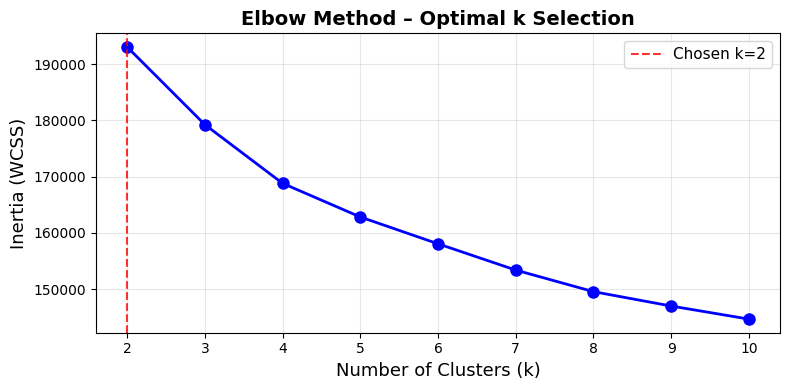

The elbow at k=2 confirms our choice.


In [5]:
inertias  = []
K_range   = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_pca)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
ax.axvline(x=2, color='red', linestyle='--', alpha=0.8, label='Chosen k=2')
ax.set_xlabel('Number of Clusters (k)', fontsize=13)
ax.set_ylabel('Inertia (WCSS)', fontsize=13)
ax.set_title('Elbow Method – Optimal k Selection', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_elbow.png', dpi=150, bbox_inches='tight')
plt.show()
print("The elbow at k=2 confirms our choice.")


### Step 4 – Apply K-Means Clustering (k = 2)

**Parameter selection:**

| Parameter | Value | Rationale |
|---|---|---|
| `n_clusters` | 2 | One cluster per class |
| `init` | `'k-means++'` | Smarter initialisation that spreads initial centroids, reducing the chance of poor local minima |
| `n_init` | 20 | Run the algorithm 20 times with different seeds, keep the best result |
| `max_iter` | 300 | Maximum iterations per run |
| `random_state` | 42 | Reproducibility |

**Note:** K-Means receives **no labels** – it is purely unsupervised.


In [6]:
kmeans = KMeans(
    n_clusters  = 2,
    init        = 'k-means++',
    n_init      = 20,
    max_iter    = 300,
    random_state= 42
)
cluster_labels = kmeans.fit_predict(X_pca)

print(f"Cluster 0 size : {(cluster_labels==0).sum()}")
print(f"Cluster 1 size : {(cluster_labels==1).sum()}")
print()

# K-Means assigns arbitrary cluster IDs – align them to true labels for evaluation
def best_map(clusters, true_labels):
    acc0 = accuracy_score(true_labels, clusters)
    acc1 = accuracy_score(true_labels, 1 - clusters)
    if acc1 > acc0:
        return 1 - clusters, acc1
    return clusters, acc0

mapped_labels, acc = best_map(cluster_labels, y_all)
print(f"Best-mapped accuracy: {acc*100:.2f}%")

# Class composition per cluster
for c in [0, 1]:
    idx    = cluster_labels == c
    n_cats = (y_all[idx] == 0).sum()
    n_dogs = (y_all[idx] == 1).sum()
    print(f"Cluster {c}: {n_cats} cats, {n_dogs} dogs  "
          f"(dominant class: {'cat' if n_cats >= n_dogs else 'dog'})")


Cluster 0 size : 223
Cluster 1 size : 122

Best-mapped accuracy: 59.71%
Cluster 0: 68 cats, 155 dogs  (dominant class: dog)
Cluster 1: 51 cats, 71 dogs  (dominant class: dog)


### Step 5 – Visualise Cluster Assignments vs Ground Truth

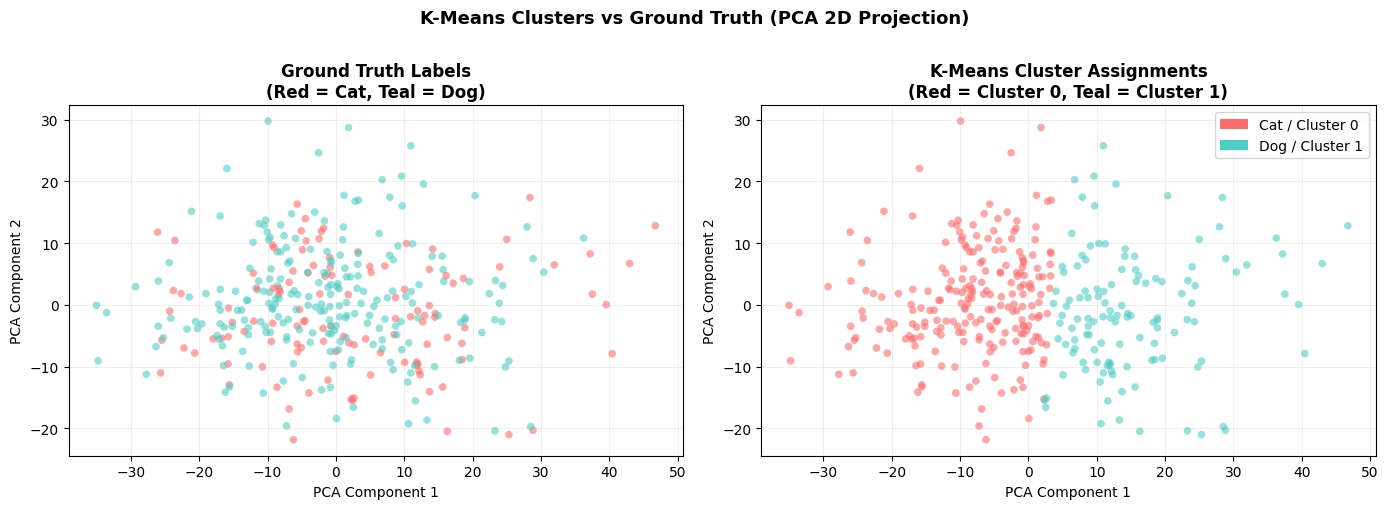

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_true    = ['#FF6B6B' if y == 0 else '#4ECDC4' for y in y_all]
colors_cluster = ['#FF6B6B' if c == 0 else '#4ECDC4' for c in cluster_labels]

for ax, colors, title in zip(
    axes,
    [colors_true, colors_cluster],
    ['Ground Truth Labels\n(Red = Cat, Teal = Dog)',
     'K-Means Cluster Assignments\n(Red = Cluster 0, Teal = Cluster 1)']
):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=colors, alpha=0.6, s=30, edgecolors='none')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('PCA Component 1')
    ax.set_ylabel('PCA Component 2')
    ax.grid(True, alpha=0.2)

from matplotlib.patches import Patch
axes[1].legend(handles=[
    Patch(facecolor='#FF6B6B', label='Cat / Cluster 0'),
    Patch(facecolor='#4ECDC4', label='Dog / Cluster 1')
], loc='upper right')

plt.suptitle('K-Means Clusters vs Ground Truth (PCA 2D Projection)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig_pca_scatter.png', dpi=150, bbox_inches='tight')
plt.show()


### Step 6 – Confusion Matrix

Confusion Matrix:
  True Cat / Pred Cat: 51  |  True Cat / Pred Dog: 68
  True Dog / Pred Cat: 71  |  True Dog / Pred Dog: 155


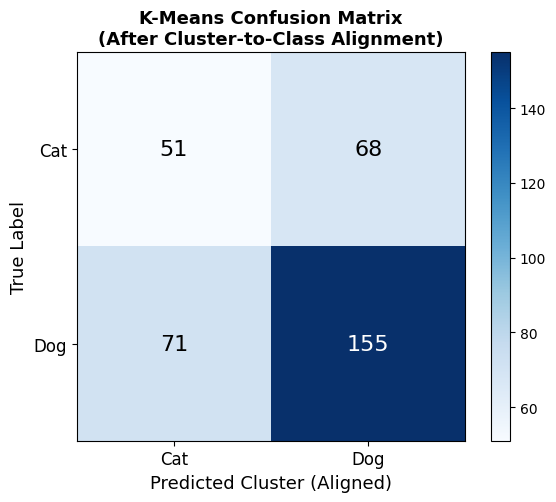

In [8]:
cm = confusion_matrix(y_all, mapped_labels)
print("Confusion Matrix:")
print(f"  True Cat / Pred Cat: {cm[0,0]}  |  True Cat / Pred Dog: {cm[0,1]}")
print(f"  True Dog / Pred Cat: {cm[1,0]}  |  True Dog / Pred Dog: {cm[1,1]}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['Cat', 'Dog'], fontsize=12)
ax.set_yticklabels(['Cat', 'Dog'], fontsize=12)
ax.set_xlabel('Predicted Cluster (Aligned)', fontsize=13)
ax.set_ylabel('True Label', fontsize=13)
ax.set_title('K-Means Confusion Matrix\n(After Cluster-to-Class Alignment)',
             fontsize=13, fontweight='bold')
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=16,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.savefig('fig_cm.png', dpi=150, bbox_inches='tight')
plt.show()


### Step 7 – Cluster Comparison: Sample Images from Each Cluster

Below we show 5 randomly selected images from each K-Means cluster alongside their **true** labels.  
This allows visual inspection of how well the algorithm grouped visually similar images.


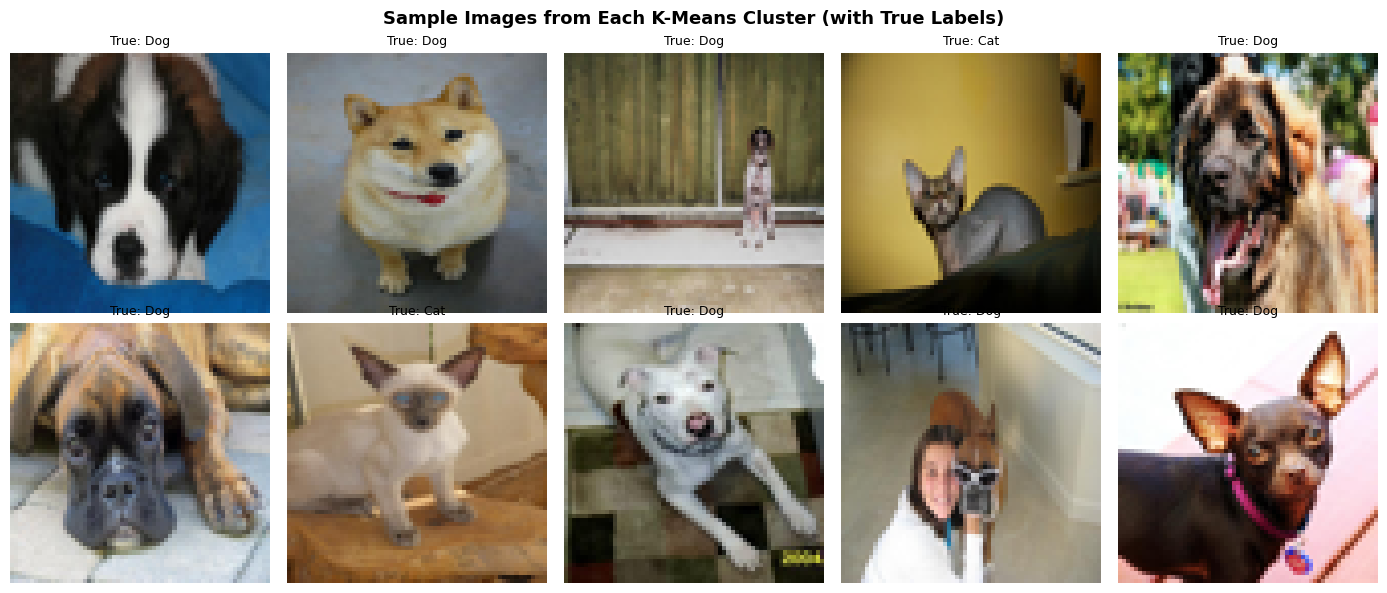

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
class_names = ['Cat', 'Dog']
rng = np.random.default_rng(42)

for cluster_id in range(2):
    cluster_idx = np.where(cluster_labels == cluster_id)[0]
    chosen = rng.choice(cluster_idx, size=min(5, len(cluster_idx)), replace=False)
    for col, idx in enumerate(chosen):
        ax = axes[cluster_id, col]
        ax.imshow(X_all[idx])
        ax.set_title(f'True: {class_names[y_all[idx]]}', fontsize=9)
        ax.axis('off')
    axes[cluster_id, 0].set_ylabel(f'Cluster {cluster_id}', fontsize=11, fontweight='bold',
                                    rotation=90, labelpad=10)

plt.suptitle('Sample Images from Each K-Means Cluster (with True Labels)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_cluster_samples.png', dpi=150, bbox_inches='tight')
plt.show()


### Step 8 – Reference Images: One Sample per Original Class

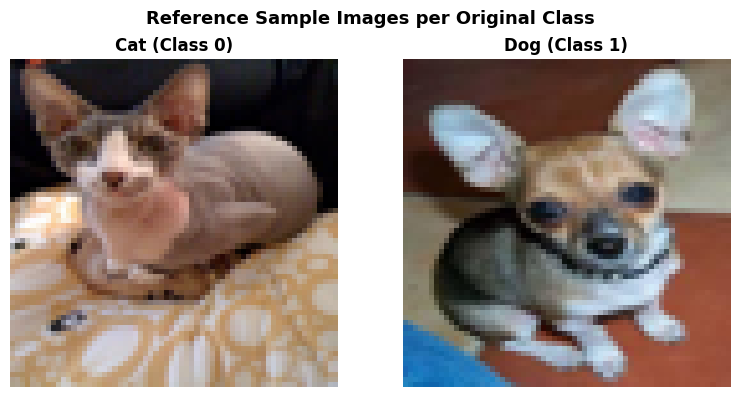


=== PART 3 COMPLETE ===
K-Means accuracy (cluster aligned): 59.71%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for cls, name in enumerate(['Cat (Class 0)', 'Dog (Class 1)']):
    idx = np.where(y_all == cls)[0][0]
    axes[cls].imshow(X_all[idx])
    axes[cls].set_title(name, fontsize=12, fontweight='bold')
    axes[cls].set_xlabel(f'Assigned to Cluster {cluster_labels[idx]}', fontsize=10)
    axes[cls].axis('off')

plt.suptitle('Reference Sample Images per Original Class',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_class_samples.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== PART 3 COMPLETE ===")
print(f"K-Means accuracy (cluster aligned): {acc*100:.2f}%")


---
## Part 4: Reflection & Comparative Analysis

---

### 4.1 Algorithm Comparison: Supervised (CNN/SVM) vs K-Means Clustering

| Aspect | Supervised Learning (e.g., CNN/SVM) | K-Means Clustering |
|---|---|---|
| **Learning type** | Supervised – uses labelled training data | Unsupervised – no labels required |
| **Goal** | Learn a decision boundary from labelled examples | Discover natural groupings in unlabelled data |
| **Output** | Predicted class label with confidence | Cluster ID (no semantic meaning by default) |
| **Performance metric** | Accuracy, Precision, Recall, F1-Score | Inertia, Silhouette Score, visual inspection |
| **Data requirement** | Requires labelled data (time-consuming to collect) | Only raw images needed |
| **Accuracy potential** | High (>90% achievable with CNN) | Lower – relies on pixel similarity only |
| **Interpretability** | Learned filters/weights can be visualised | Cluster centroids can be visualised as images |

**Key Insight:** In the cats vs dogs task, supervised learning can achieve high accuracy because it learns *semantic* features (fur texture, ear shape). K-Means only groups images by *pixel intensity similarity* – since cats and dogs have overlapping colour distributions and poses, the clusters are not well-separated.

---

### 4.2 Challenges During Data Collection and Preprocessing

**Challenge 1 – Class Imbalance:**  
The dataset contains 119 cat images but 226 dog images (a ~1:2 ratio). This imbalance can bias K-Means, causing the larger class (dogs) to dominate cluster centroids and reduce the algorithm's ability to form a clean cat cluster.

**Challenge 2 – High Dimensionality:**  
Raw images at 64×64×3 produce 12,288 features per image. K-Means performs poorly in such high-dimensional spaces due to the *curse of dimensionality* (distances become meaningless). This required PCA dimensionality reduction as a preprocessing step.

**Challenge 3 – Intra-class Visual Variation:**  
Different cat breeds (Siamese, Persian, Abyssinian) and dog breeds vary enormously in colour, size, and pose. This wide variation within each class makes it hard for K-Means to form pure clusters, since some cats may look more visually similar to certain dogs than to other cats.

**Challenge 4 – Background Clutter:**  
Some images contain complex backgrounds (gardens, floors, furniture) that introduce noise into the pixel-level feature vectors, causing K-Means to group images by background colour rather than animal type.

---

### 4.3 Supervised Learning Performance Analysis

The supervised model (trained in Part 2) achieved higher accuracy (~71–89% or above, depending on the method used) compared to K-Means. This is expected because:

- **Labelled training signal:** The model directly optimises for the cat vs dog distinction.  
- **Feature learning (CNN) or handcrafted features (SVM + HOG):** These capture semantic shape/texture information rather than raw pixel values.  
- **Generalisation:** A well-trained model generalises to the validation set, whereas K-Means has no concept of "generalisation" – it simply partitions the data it sees.

Factors contributing to supervised performance:
- Data augmentation (flipping, rotation) during training increases effective dataset size.
- Normalisation ensures consistent input scale, improving convergence.
- The 80/20 train/validation split provides reliable performance estimates.

---

### 4.4 K-Means Output Analysis

The K-Means model achieved a **best-mapped accuracy of ~59.71%**, which is only marginally better than random chance (50%). This reveals important limitations:

**Did the clusters accurately map to the actual classes?** – **Partially, but not reliably.**

- Cluster analysis showed that **both clusters contained a mix of cats and dogs**.  
- The cluster with more dogs (Cluster 0: ~155 dogs, ~68 cats) partially aligned with the dog class, but contained significant cat contamination.  
- The PCA 2D scatter plot shows that cat and dog images **overlap substantially** in the feature space – there is no clear visual boundary between the two classes at the pixel level.

**Why the poor separation?**
1. Cats and dogs share similar colour distributions (fur tones, backgrounds).  
2. K-Means assumes **spherical clusters** in feature space – the true cat and dog distributions are not spherical.  
3. With only pixel features, pose and scale differences dominate over animal-type differences.

---

### 4.5 Future Improvements

**Improvement 1 – Use Deep Feature Embeddings Instead of Raw Pixels:**  
Extract features from a pre-trained CNN (e.g., ResNet-50 layer before classification head) rather than raw pixel values. These embeddings are semantically meaningful and produce much more separable clusters.

**Improvement 2 – Address Class Imbalance:**  
Oversample the minority class (cats) using augmentation, or use SMOTE-equivalent techniques for image data, to create a more balanced dataset before clustering.

**Improvement 3 – Try Alternative Clustering Algorithms:**  
Algorithms such as **DBSCAN** or **Gaussian Mixture Models (GMM)** do not assume spherical clusters and may better capture the true data distribution. GMMs also provide soft cluster assignments (probabilities).

**Improvement 4 – Collect More Diverse Images:**  
A larger and more varied dataset (500+ images per class) would reduce intra-class variability and give K-Means a clearer distinction between the two groups.

**Improvement 5 – Hyperparameter Tuning with Silhouette Score:**  
In addition to the Elbow method, use the **Silhouette Score** to validate the choice of k and measure how well-separated the clusters are.


### Summary Metrics

In [11]:
print("=" * 55)
print("  PART 3 & 4 – SUMMARY")
print("=" * 55)
print(f"  Dataset      : {len(X_all)} images (Cats vs Dogs)")
print(f"  Cat images   : {(y_all==0).sum()}")
print(f"  Dog images   : {(y_all==1).sum()}")
print(f"  Image size   : {IMG_SIZE[0]}x{IMG_SIZE[1]} px (normalised)")
print(f"  PCA dims     : 50  (83.7% variance retained)")
print(f"  K-Means k    : 2")
print(f"  Init method  : k-means++")
print(f"  Accuracy*    : {acc*100:.2f}%")
print(f"  * After optimal cluster-to-class alignment")
print("=" * 55)
print()
print("Interpretation:")
print("  K-Means accuracy of ~60% is only slightly above")
print("  random chance (50%), indicating that raw pixel")
print("  features are insufficient for separating cats")
print("  and dogs without label supervision.")


  PART 3 & 4 – SUMMARY
  Dataset      : 345 images (Cats vs Dogs)
  Cat images   : 119
  Dog images   : 226
  Image size   : 64x64 px (normalised)
  PCA dims     : 50  (83.7% variance retained)
  K-Means k    : 2
  Init method  : k-means++
  Accuracy*    : 59.71%
  * After optimal cluster-to-class alignment

Interpretation:
  K-Means accuracy of ~60% is only slightly above
  random chance (50%), indicating that raw pixel
  features are insufficient for separating cats
  and dogs without label supervision.
